# BSP project

*Giacomo Sacco 82389A*

Algorithm implemetation of the paper:

"A wavelet-based ECG delineation algorithm for 32-bit integer online processing" (2011) by Luigi Di Marco and Lorenzo Chiari

In [73]:
import numpy as np
import pywt
from scipy.signal import find_peaks, resample
import wfdb
import matplotlib.pyplot as plt
from ecg_utils import load_ecg, load_annotations, plot_ecg, plot_ecg_interactive, load_ecg_int

In [74]:
# MIT-BIH Arrhythmia Database record names
mit_bih_records = [
    '100', '101', '102', '103', '104', '105', '106', '107', '108', '109',
    '111', '112', '113', '114', '115', '116', '117', '118', '119', '121',
    '122', '123', '124', '200', '201', '202', '203', '205', '207', '208',
    '209', '210', '212', '213', '214', '215', '217', '219', '220', '221',
    '222', '223', '228', '230', '231', '232', '233', '234'
]
current = 10
path = "../data/mit-bih-arrhythmia-database-1.0.0"
len(mit_bih_records)

48

In [75]:
ecg, fs, record = load_ecg_int(mit_bih_records[current], path)
annotations = load_annotations(mit_bih_records[current], path)

## Preprocessing
- downsample to 250 sample/s
- 

In [76]:
# downsample ecg signal to 250 Hz
new_fs = 250
ecg = resample(ecg, int(len(ecg) * new_fs / fs))
fs = new_fs

## DWT decomposition

In [77]:
def remove_group_delay(details):
    '''
    Remove group delay from detail coefficients. 
    Using 4.1 formula from the paper. 
    input: details - detail coefficents of the wavelet filter
    output: details - shifted version of the detail coefficents
    '''
    for k in details.keys():
        tau = 0
        for l in range(1, k-1):
            tau_H = -3 * 2**(l -2)
            tau_G = -2**(k-2)
            tau += tau_H + tau_G
        print(f'level {k}: group delay = {tau} samples')
        details[k] = np.roll(details[k], -tau)
    return details
    

def integer_wavelet_transform(ecg_signal, levels=4):
    '''
    Perform Integer Wavelet Transform using the "algorithme à trous" method.
    input: ecg_signal - raw ECG signal
           levels - number of decomposition levels (default 4)
    output: details - dictionary of detail coefficients at each level
            approximation - final approximation coefficients
    '''
    # 32-bit integer conversion (to avoid overflow during summation)
    signal = np.array(ecg_signal, dtype=np.int32)

    # Base coefficients (Numerators from Table 1)
    h_coeffs = np.array([1, 7, 21, 35, 35, 21, 7, 1], dtype=np.int32)
    g_coeffs = np.array([-2, 2], dtype=np.int32)
    
    # Dictionary to store detail coefficients (d1, d2, d3, d4, ...)
    details = {}
    approximation = signal 
    
    # Loop for scales from 1 to 4 (2^1 to 2^4)
    for k in range(1, levels+1):
        # --- A. FILTER PREPARATION (ALGORITHME À TROUS) ---
        # At each scale k, insert 2^(k-1) - 1 zeros between coefficients
        step = 2**(k-1)
        
        # Create "dilated" filters with zeros (the "holes")
        h_k = np.zeros(len(h_coeffs) * step - (step-1), dtype=np.int32)
        h_k[::step] = h_coeffs
        # g_k is time-reversed version of g_coeffs because otherwise detail coefficients are inverted
        g_k = np.zeros(len(g_coeffs[::-1]) * step - (step-1), dtype=np.int32)
        g_k[::step] = g_coeffs[::-1]

        # --- B. CONVOLUTION (Shift & Add) ---
        # Calculate the next Approximation (A_k) using h_k
        # 'same' keeps the length the same (not decimated)
        a_next_num = np.convolve(approximation, h_k, mode='same')
        # Integer division via bit-shift: divided by 128 is shift >> 7
        a_next = np.right_shift(a_next_num, 7)
        
        # Calculate the Detail (d_k) using g_k
        # g has no divisor in Table 1, it is just differential [-2, 2]
        d_next = np.convolve(approximation, g_k, mode='same')
        
        # remove beginning and end artifacts due to convolution on detail coefficients
        mean_d = np.mean(d_next)
        d_next[:len(h_k)//2] = mean_d
        d_next[-(len(h_k)//2):] = mean_d

        details[k] = d_next
        approximation = a_next # The input for the next iteration is the current approximation
    
    details = remove_group_delay(details)

    return details, approximation

details, approximation = integer_wavelet_transform(ecg, 5)

level 1: group delay = 0 samples
level 2: group delay = 0 samples
level 3: group delay = -3.5 samples
level 4: group delay = -12.5 samples
level 5: group delay = -34.5 samples


(2.0, 5.0)

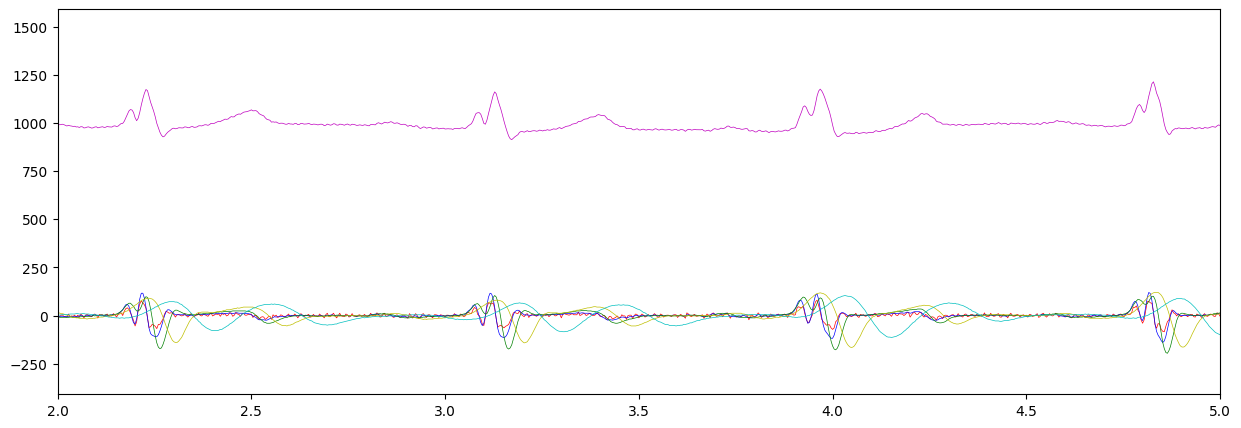

In [78]:
# Create time array
time = np.arange(len(ecg)) / fs

# Plot ECG signal
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(time, ecg, 'm-', linewidth=0.5, label='ECG')
ax.plot(time, details[1], 'r-', linewidth=0.5, label='ECG')
ax.plot(time, details[2], 'b-', linewidth=0.5, label='ECG')
ax.plot(time, details[3], 'g-', linewidth=0.5, label='ECG')
ax.plot(time, details[4], 'y-', linewidth=0.5, label='ECG')
ax.plot(time, details[5], 'c-', linewidth=0.5, label='ECG')
ax.set_xlim(2, 5)

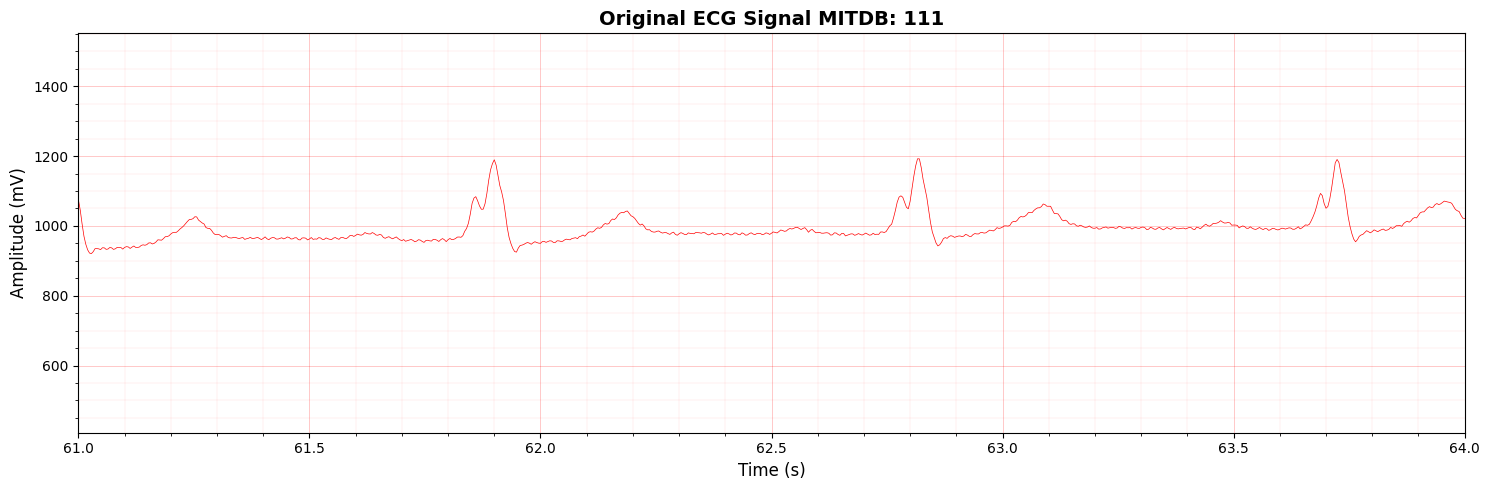

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz


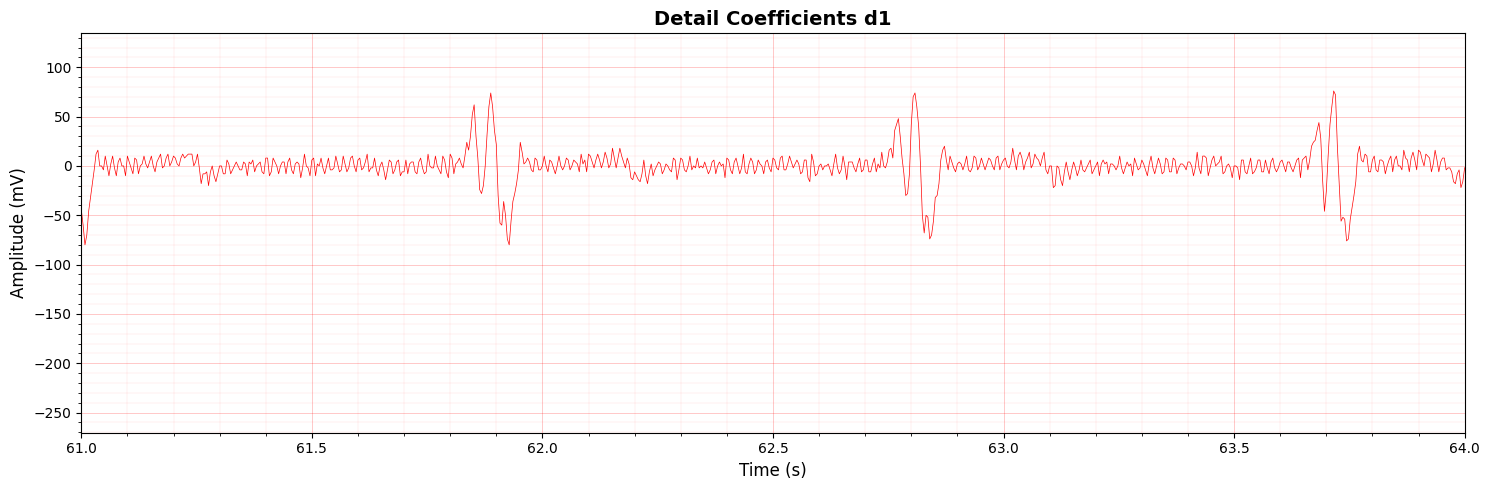

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz


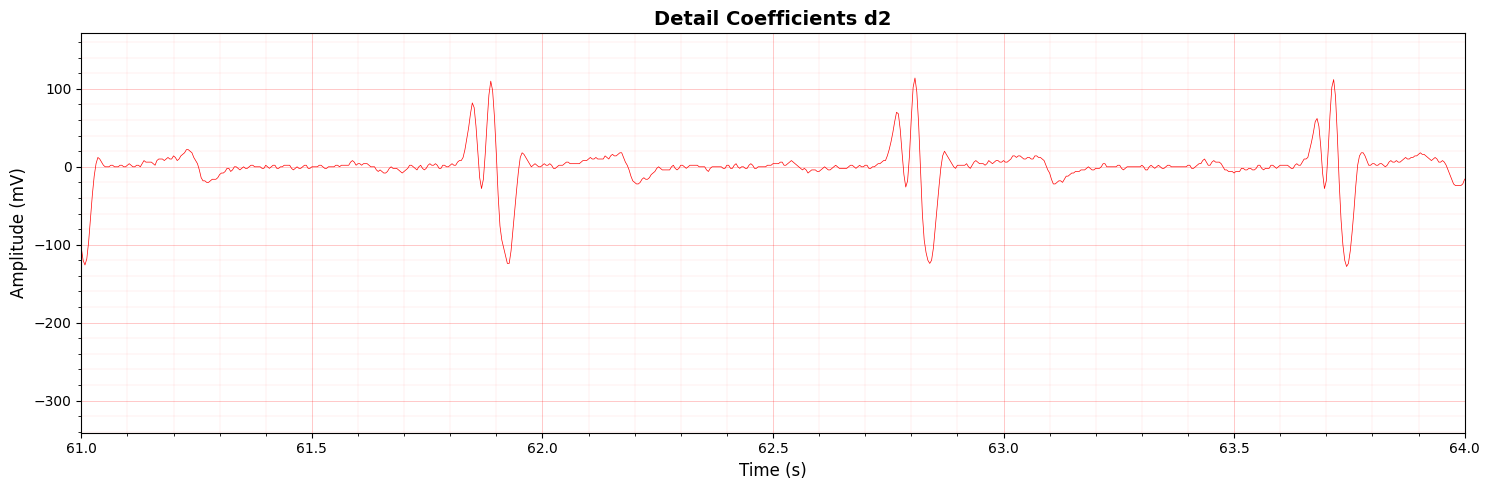

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz


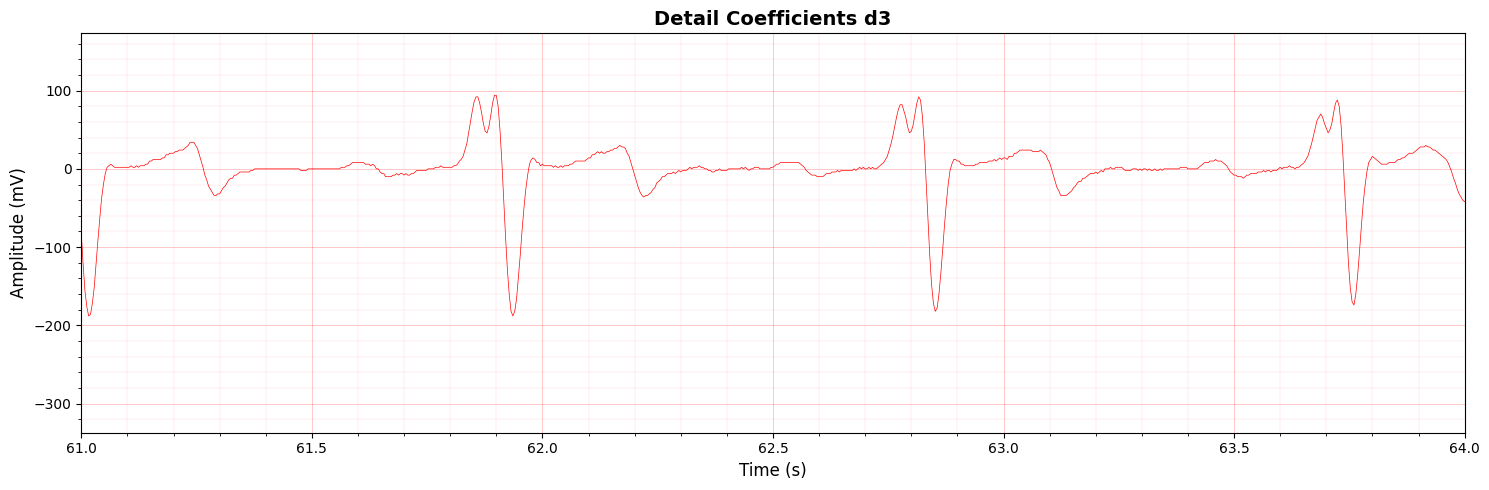

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz


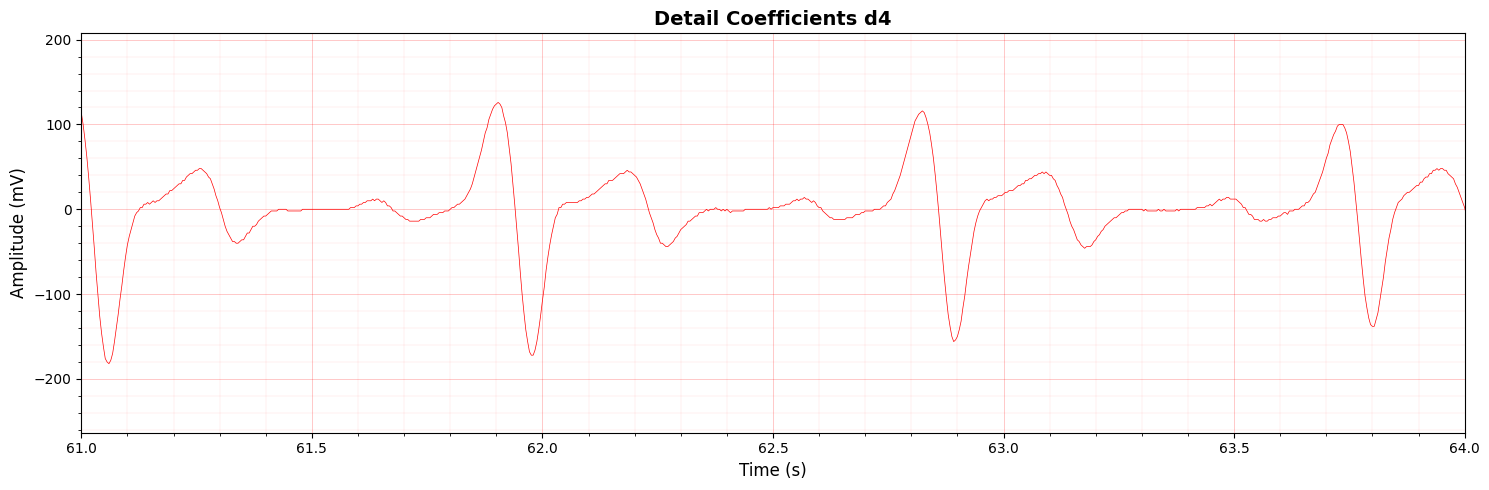

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz


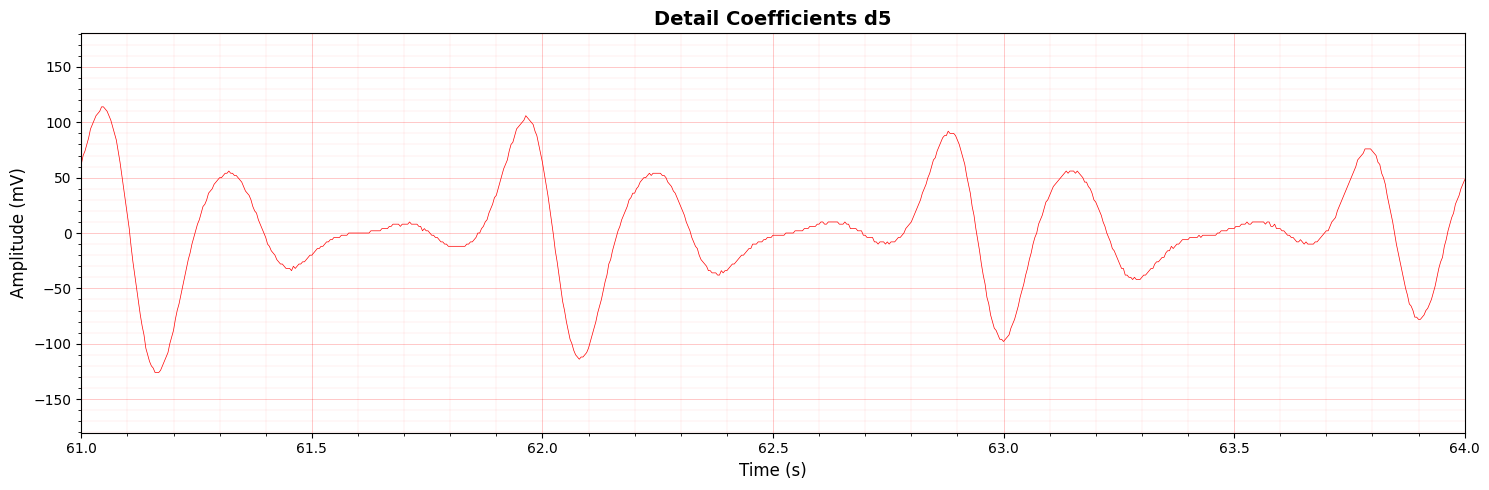

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz


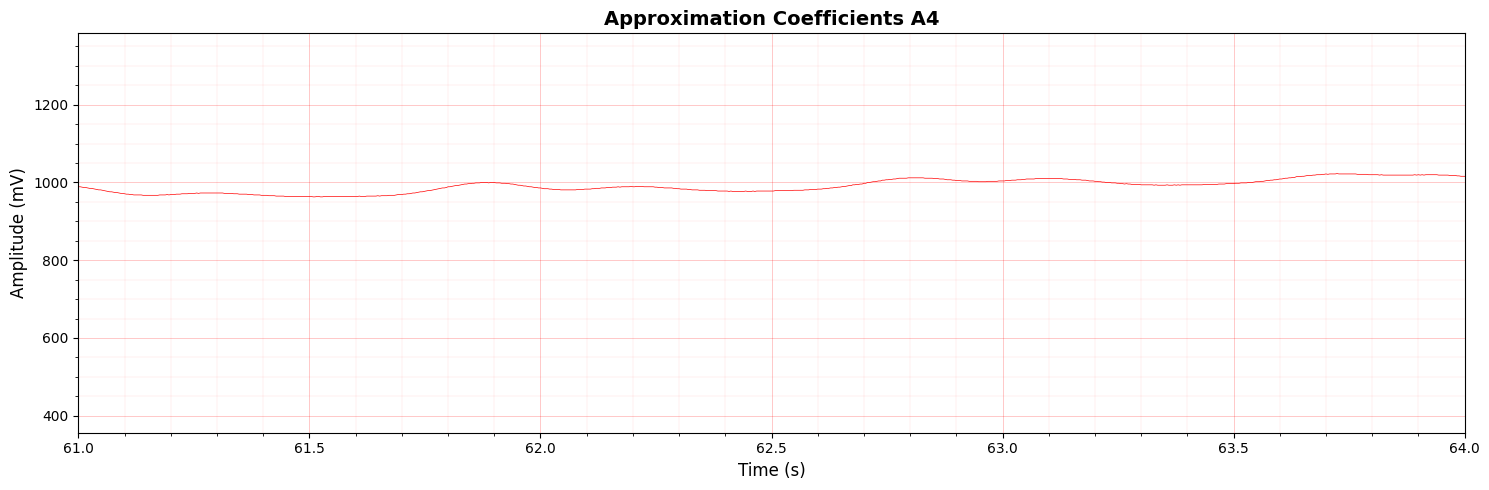

Total duration: 1805.6 seconds
Sampling frequency: 250 Hz


In [79]:
time_range = (61, 64)
plot_ecg(ecg, fs, time_range = time_range, title=f'Original ECG Signal MITDB: {mit_bih_records[current]}')
for level in details:
    plot_ecg(details[level], fs, time_range = time_range, title=f'Detail Coefficients d{level}')
plot_ecg(approximation, fs, time_range = time_range, title='Approximation Coefficients A4')

## Online QRS detection and P-QRS-T delineation

###  QRS-complex detection


In [80]:
def max_min_difference(signal):
    '''Calculate the difference between the maximum and minimum value in a vector'''
    max = np.max(signal)
    min = np.min(signal)
    delta = max - min
    return delta

def is_zero_crossing(signal, i):
    '''
    Calculate if two point are a zero-crossing. 
    If they are return the AMMp value, otherwise return 0.
    '''
    # Check if there is a zero crossing between i-1 and i
    if (signal[i-1] <= 0 and signal[i] > 0) or (signal[i-1] > 0 and signal[i] <= 0):
        # search left
        j = i - 1
        loc_max = abs(signal[j])
        while j > 0 and abs(signal[j-1]) >= loc_max:
            j -= 1
            loc_max = abs(signal[j])
        left_peak = abs(signal[j+1])
        # search right
        j = i
        loc_max = abs(signal[j])
        while  j < len(signal)-1 and abs(signal[j+1]) >= loc_max:
            j += 1
            loc_max = abs(signal[j])
        right_peak = abs(signal[j-1])
        # calculate Adjacent Modulus Maxima pair
        AMMp = left_peak + right_peak
    else:
        AMMp = 0
    return AMMp

def QRS_detection(details, fs):
    '''
    Docstring for QRS_detection
    
    :param details: detail coefficents from WT
    :param fs: sampling frequency
    '''
    # detail levels used
    d2=details[2]
    d3=details[3]
    qrs_positions = []                  # found qrs postions
    qrs_d2_delta = []                   # qrs min-max delta on d^2
    qrs_d3_delta = []                   # qrs min-max delta on d^3
    qrs_found = 0                       # number of QRS found
    deltaWQRS = np.right_shift(fs, 2)   # observation window = 250 ms
    deltaW100 = int(fs * 0.1)           # half-window samples number for detection rules
    i_zc = np.int64(1)
    signal_length = len(d2)

     # search zero-crossings in detail level 2^2
    while i_zc < signal_length:
        AMMp = is_zero_crossing(d2, i_zc)   # Adjacent Modulus Maxima pair
        # if zero-crossing (ZCs) is found (AMMp>0) start looking for 
        # better ZCs (bigger AMMp) in the observation window
        if AMMp > 0:
            j_zc = i_zc + 1
            # iterate in the observation window looking for better QRS-candidates
            while j_zc < i_zc + deltaWQRS and j_zc < signal_length:
                AMMp_new = is_zero_crossing(d2, j_zc)
                # if a bigger AMMp is found, restart the obs. window
                if AMMp_new > AMMp:
                    AMMp = AMMp_new
                    i_zc = j_zc # new QRS candidate found
                else:
                    j_zc += 1

            # QRS candidate decision  
            delta_window = max(0, i_zc-deltaW100), min(signal_length-1, i_zc+deltaW100)
            e_start = max(0, qrs_found-4)
            zc_d2_delta = max_min_difference(d2[delta_window[0]:delta_window[1]])
            epsilon_d2 = np.right_shift(11 * sum(qrs_d2_delta[e_start:qrs_found]), 7)
            # first test on d^2
            if zc_d2_delta > epsilon_d2:
                zc_d3_delta = max_min_difference(d3[delta_window[0]:delta_window[1]])
                epsilon_d3 = np.right_shift(11 * sum(qrs_d3_delta[e_start:qrs_found]), 7)
                # second test on d^3
                if zc_d3_delta > epsilon_d3:
                    # QRS-candidate ACCEPTED
                    qrs_positions.append(i_zc)
                    qrs_d2_delta.append(zc_d2_delta)
                    qrs_d3_delta.append(zc_d3_delta)
                    qrs_found += 1
            i_zc += deltaWQRS + 1
        else:
            i_zc += 1
    #return qrs_positions[4:]
    return qrs_positions

qrs_postitions = QRS_detection(details, fs)

In [81]:
len(qrs_postitions), len(annotations.sample)

(2135, 2133)

(60.0, 63.0)

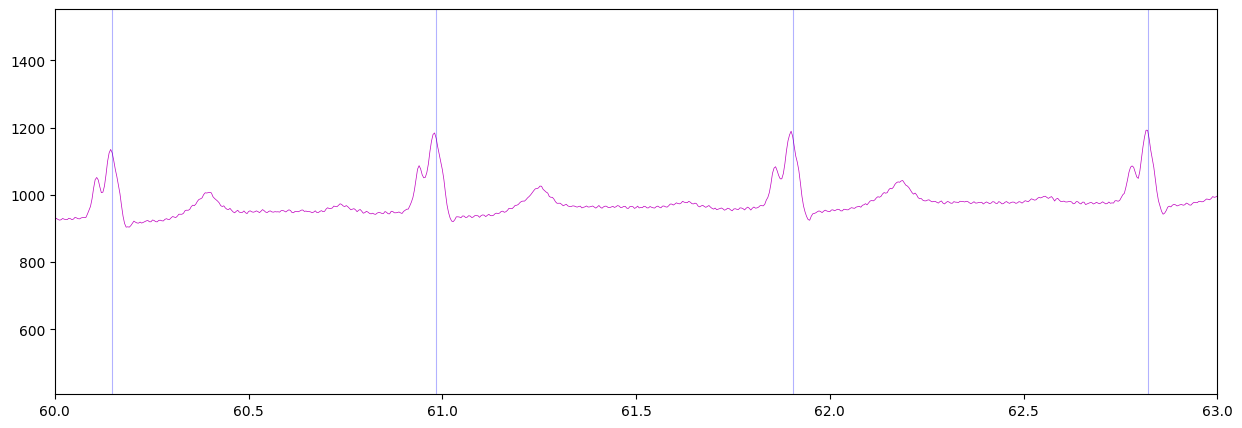

In [82]:
# Create time array
time = np.arange(len(ecg)) / fs

# Plot ECG signal
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(time, ecg, 'm-', linewidth=0.5, label='ECG')
for t in qrs_postitions:
    ax.axvline(t/fs, color='blue', alpha=0.3, linewidth=0.8)
ax.set_xlim(60, 63)

###  QRS-complex delineation (onset/offset)


### P detection (mono & biphasic)

### T detection (mono & biphasic)